# California Housing Price Prediction

## Project overview

This project builds regression models to estimate California district-level median house values using the supplied `housing.csv` dataset.

The notebook retains the original project's analytical workflow:

- Dataset inspection and data-quality checks
- Exploratory data analysis (EDA) and visualizations
- Median imputation and household-level feature engineering
- One-hot encoding of `ocean_proximity`
- Standard scaling of numerical features
- Comparison of five regression algorithms
- Randomized hyperparameter search for HistGradientBoostingRegressor
- Regression evaluation, residual analysis, and permutation importance
- Model export and prediction examples

**Target variable:** `median_house_value`

**Important evaluation improvement:** preprocessing is fitted within scikit-learn pipelines. This means imputation, encoding, and scaling are learned only from each training fold and never from the held-out test set.

## 1. Project setup and library imports

The project uses a small helper module in `src/` for reproducible feature engineering. Output folders are created automatically.

In [1]:
from pathlib import Path
import sys
import os
import json
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# Keep notebook output readable while retaining meaningful warnings.
warnings.filterwarnings("default")
sns.set_theme(style="whitegrid")

# Locate the project root whether the notebook is launched from the root
# directory or from the notebooks/ directory.
current_directory = Path.cwd()
possible_roots = [
    current_directory,
    current_directory.parent,
    current_directory.parent.parent,
]
PROJECT_ROOT = next(
    (path for path in possible_roots if (path / "Dataset" / "housing.csv").exists()),
    current_directory,
)

# Make the project's src/ package available for imports and model loading.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.housing_features import HousingFeatureEngineer

DATA_PATH = PROJECT_ROOT / "Dataset" / "housing.csv"
VISUALIZATION_DIR = PROJECT_ROOT / "visualizations"
MODEL_DIR = PROJECT_ROOT / "models"

VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TARGET = "median_house_value"

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {DATA_PATH}")
print(f"scikit-learn version: {sklearn.__version__}")

Project root: C:\Users\mosad\Downloads\Housing_Price_ML_Project\Housing_Price_ML_Project
Dataset path: C:\Users\mosad\Downloads\Housing_Price_ML_Project\Housing_Price_ML_Project\Dataset\housing.csv
scikit-learn version: 1.9.0


## 2. Reusable visualization-saving function

Every chart in this notebook is saved as a high-resolution PNG (300 DPI) before it is displayed. If a filename already exists, a numbered suffix is used so earlier images are not overwritten.

In [2]:
def save_figure(fig, filename):
    """Save a Matplotlib figure as a 300-DPI PNG without overwriting files."""
    requested_path = VISUALIZATION_DIR / filename
    requested_path.parent.mkdir(parents=True, exist_ok=True)

    output_path = requested_path
    counter = 1

    while output_path.exists():
        output_path = requested_path.with_name(
            f"{requested_path.stem}_{counter:02d}{requested_path.suffix}"
        )
        counter += 1

    fig.savefig(
        output_path,
        format="png",
        dpi=300,
        bbox_inches="tight",
    )
    print(f"Saved visualization: {output_path.relative_to(PROJECT_ROOT)}")
    return output_path

## 3. Dataset loading

Load the supplied dataset without changing its original contents. The source CSV is retained in the `Dataset/` folder.

In [3]:
df = pd.read_csv(DATA_PATH)

if TARGET not in df.columns:
    raise ValueError(f"Expected target column '{TARGET}' was not found.")

print(f"Dataset loaded successfully: {df.shape[0]:,} rows and {df.shape[1]} columns.")
display(df.head())

Dataset loaded successfully: 20,640 rows and 10 columns.


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 4. Dataset overview and data-quality checks

Inspect the first and last records, column types, numerical summaries, categorical values, missing values, duplicates, and unique-value counts.

In [4]:
print("Last five rows:")
display(df.tail())

print(f"Dataset shape: {df.shape}")
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe())

print("\nCategorical summary:")
display(df.describe(include="object"))

Last five rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


Dataset shape: (20640, 10)

Column names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Numerical summary:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000



Categorical summary:


,ocean_proximity
count,20640
unique,5
top,<1H OCEAN
freq,9136


In [5]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(3),
})

print("Missing-value summary:")
display(missing_summary)

print(f"Duplicate rows: {df.duplicated().sum():,}")

print("\nUnique values per column:")
display(df.nunique().to_frame("Unique Values"))

Missing-value summary:


,Missing Count,Missing Percentage
longitude,0,0.000
latitude,0,0.000
housing_median_age,0,0.000
total_rooms,0,0.000
total_bedrooms,207,1.003
population,0,0.000
households,0,0.000
median_income,0,0.000
median_house_value,0,0.000
ocean_proximity,0,0.000


Duplicate rows: 0

Unique values per column:


,Unique Values
longitude,844
latitude,862
housing_median_age,52
total_rooms,5926
total_bedrooms,1923
population,3888
households,1815
median_income,12928
median_house_value,3842
ocean_proximity,5


## 5. Exploratory data analysis (EDA)

The following plots reproduce the original notebook's main EDA views. Each figure is exported to `visualizations/` before display.

Saved visualization: visualizations\01_numerical_feature_distributions.png


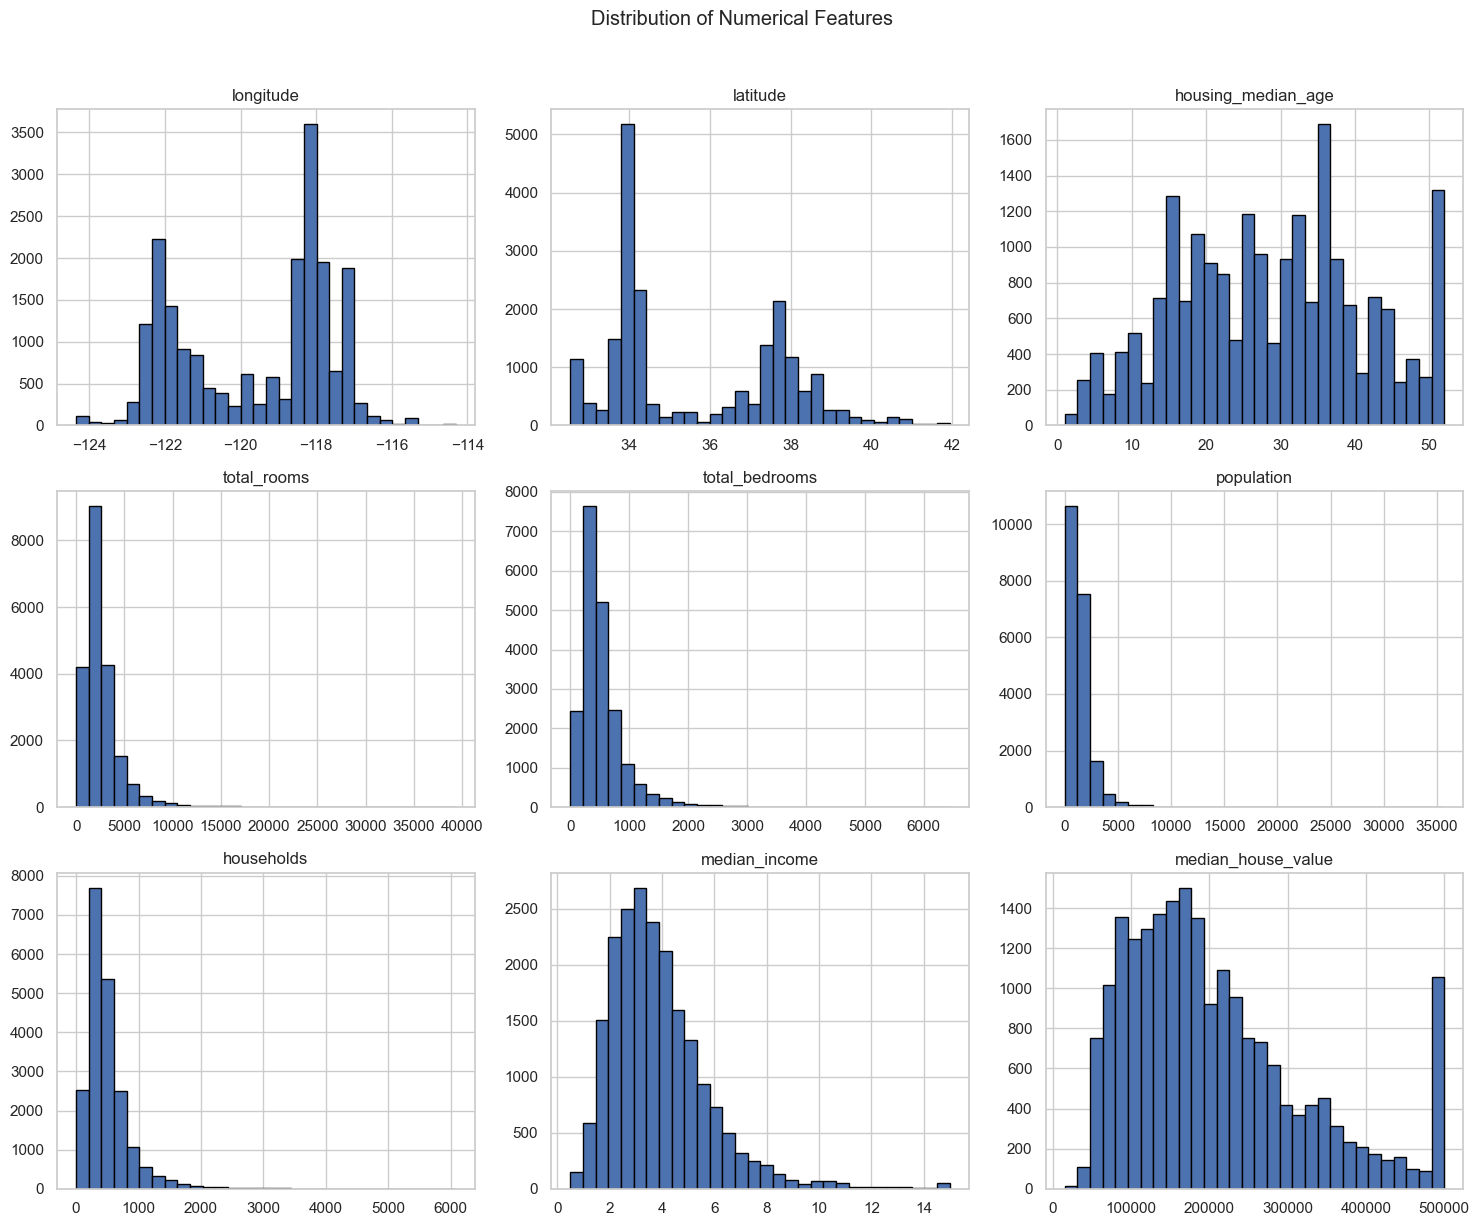

In [6]:
# Plot distributions for all numerical columns.
hist_axes = df.hist(
    bins=30,
    figsize=(15, 12),
    edgecolor="black",
)

hist_figure = hist_axes[0, 0].figure
hist_figure.suptitle("Distribution of Numerical Features", y=1.02)
hist_figure.tight_layout()

save_figure(hist_figure, "01_numerical_feature_distributions.png")
plt.show()
plt.close(hist_figure)

Saved visualization: visualizations\02_median_house_value_distribution.png


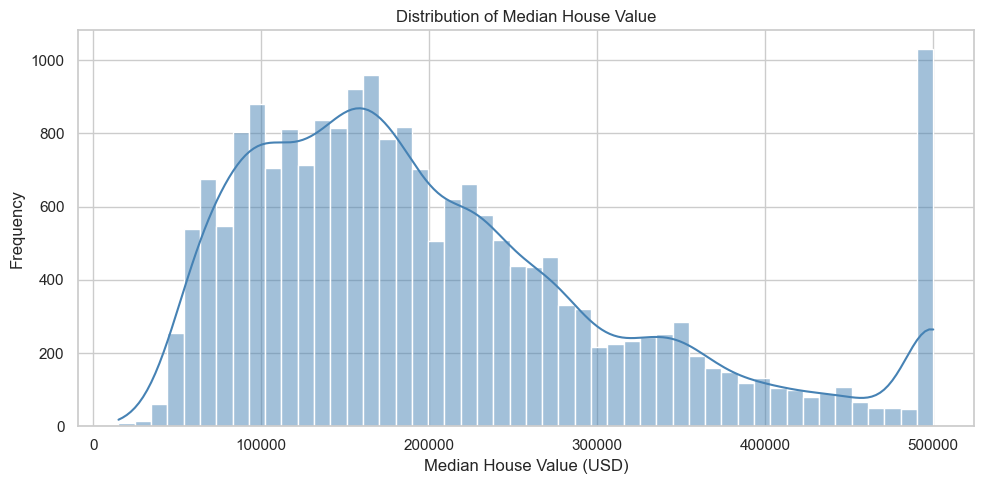

Target-variable statistics:


,Median House Value
count,20640.000000
mean,206855.816909
std,115395.615874
min,14999.000000
25%,119600.000000
50%,179700.000000
75%,264725.000000
max,500001.000000


In [7]:
# Examine the target variable's distribution.
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df,
    x=TARGET,
    bins=50,
    kde=True,
    color="steelblue",
    ax=ax,
)

ax.set_title("Distribution of Median House Value")
ax.set_xlabel("Median House Value (USD)")
ax.set_ylabel("Frequency")
fig.tight_layout()

save_figure(fig, "02_median_house_value_distribution.png")
plt.show()
plt.close(fig)

print("Target-variable statistics:")
display(df[TARGET].describe().to_frame("Median House Value"))

Saved visualization: visualizations\03_ocean_proximity_distribution.png


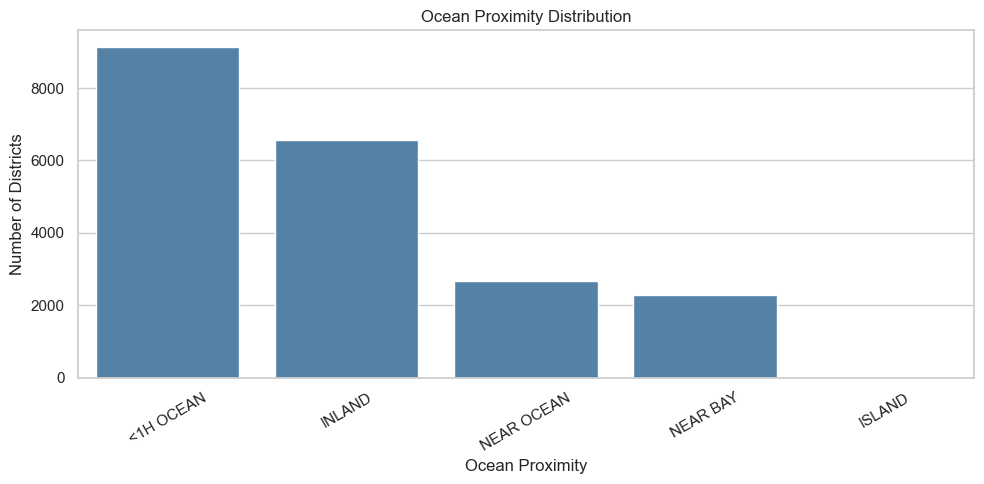

,Count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


In [8]:
# Show the number of records in each ocean-proximity category.
fig, ax = plt.subplots(figsize=(10, 5))

category_order = df["ocean_proximity"].value_counts().index

sns.countplot(
    color="steelblue",
    data=df,
    x="ocean_proximity",
    order=category_order,
    ax=ax,
)

ax.set_title("Ocean Proximity Distribution")
ax.set_xlabel("Ocean Proximity")
ax.set_ylabel("Number of Districts")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()

save_figure(fig, "03_ocean_proximity_distribution.png")
plt.show()
plt.close(fig)

display(df["ocean_proximity"].value_counts().to_frame("Count"))

Saved visualization: visualizations\04_correlation_heatmap.png


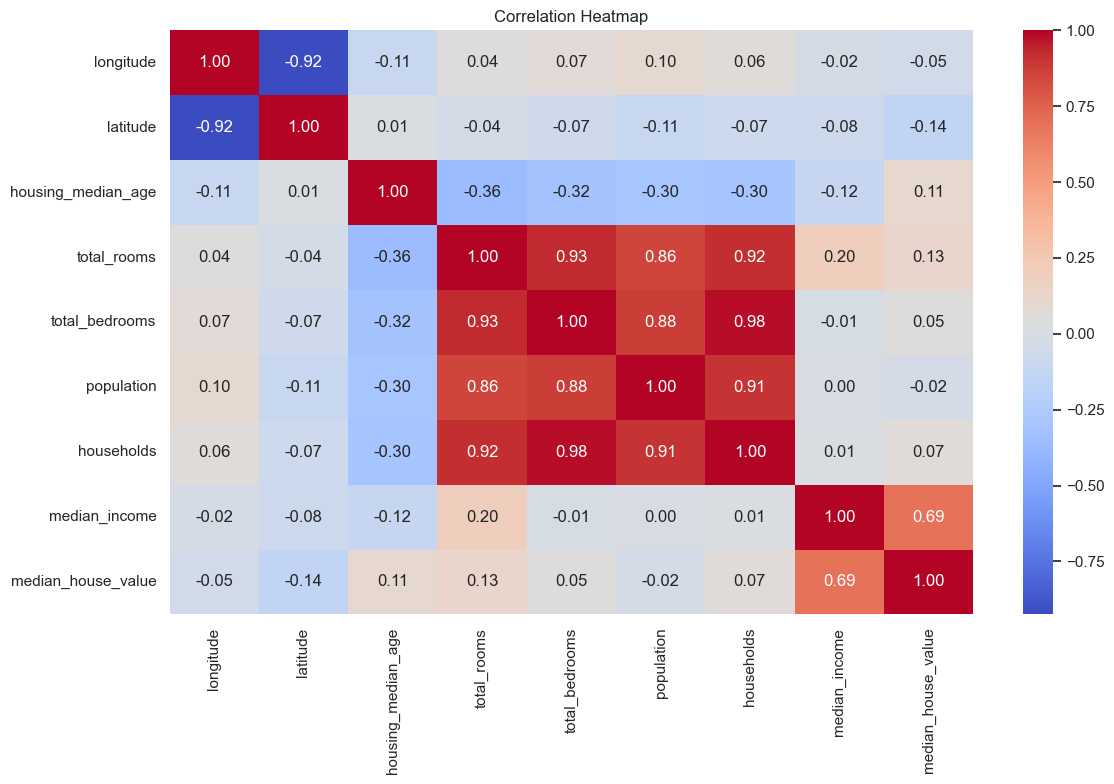

Correlation with median house value:


,Correlation
median_house_value,1.000000
median_income,0.688075
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population,-0.024650
longitude,-0.045967
latitude,-0.144160


In [9]:
# Calculate correlations for numerical columns only.
correlation_matrix = df.select_dtypes(include="number").corr()

fig, ax = plt.subplots(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    ax=ax,
)

ax.set_title("Correlation Heatmap")
fig.tight_layout()

save_figure(fig, "04_correlation_heatmap.png")
plt.show()
plt.close(fig)

print("Correlation with median house value:")
display(
    correlation_matrix[TARGET]
    .sort_values(ascending=False)
    .to_frame("Correlation")
)

Saved visualization: visualizations\05_median_income_vs_house_value.png


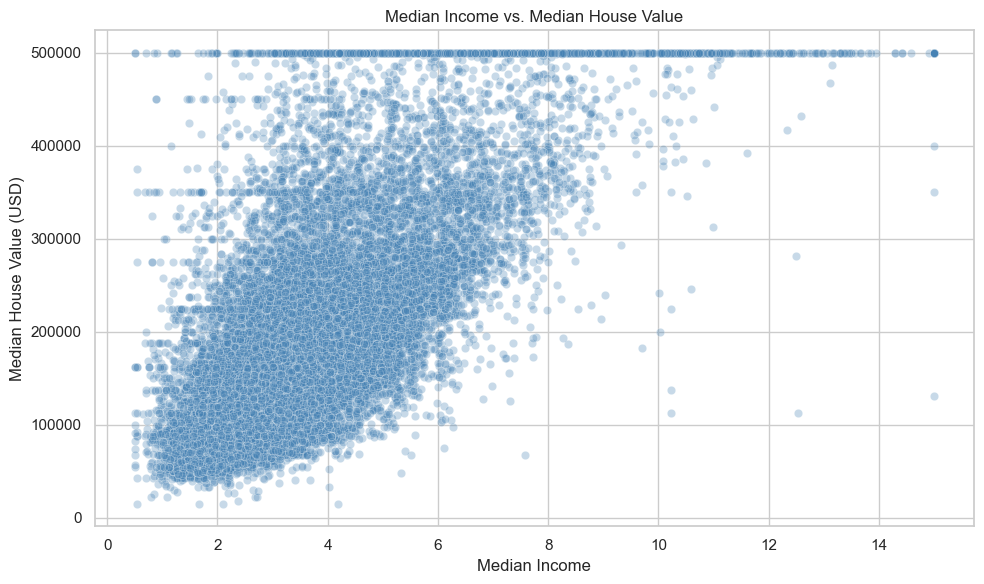

In [10]:
# Explore the relationship between median income and house value.
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    color="steelblue",
    data=df,
    x="median_income",
    y=TARGET,
    alpha=0.3,
    ax=ax,
)

ax.set_title("Median Income vs. Median House Value")
ax.set_xlabel("Median Income")
ax.set_ylabel("Median House Value (USD)")
fig.tight_layout()

save_figure(fig, "05_median_income_vs_house_value.png")
plt.show()
plt.close(fig)

C:\Users\mosad\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


Saved visualization: visualizations\06_house_prices_by_ocean_proximity.png


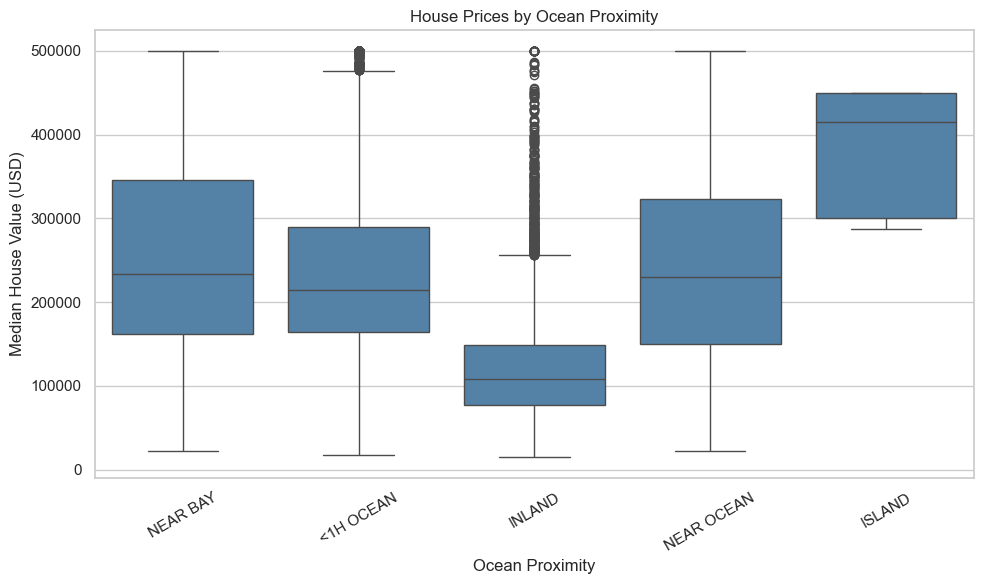

Average house value by ocean proximity:


,Average Median House Value
ocean_proximity,
INLAND,124805.392001
<1H OCEAN,240084.285464
NEAR OCEAN,249433.977427
NEAR BAY,259212.311790
ISLAND,380440.000000


In [11]:
# Compare house-value distributions across ocean-proximity groups.
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    color="steelblue",
    data=df,
    x="ocean_proximity",
    y=TARGET,
    ax=ax,
)

ax.set_title("House Prices by Ocean Proximity")
ax.set_xlabel("Ocean Proximity")
ax.set_ylabel("Median House Value (USD)")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()

save_figure(fig, "06_house_prices_by_ocean_proximity.png")
plt.show()
plt.close(fig)

print("Average house value by ocean proximity:")
display(
    df.groupby("ocean_proximity")[TARGET]
    .mean()
    .sort_values()
    .to_frame("Average Median House Value")
)

C:\Users\mosad\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\mosad\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\mosad\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\mosad\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\mosad\anaconda3\Lib\site-packages\seaborn\categ

Saved visualization: visualizations\07_numerical_feature_boxplots.png


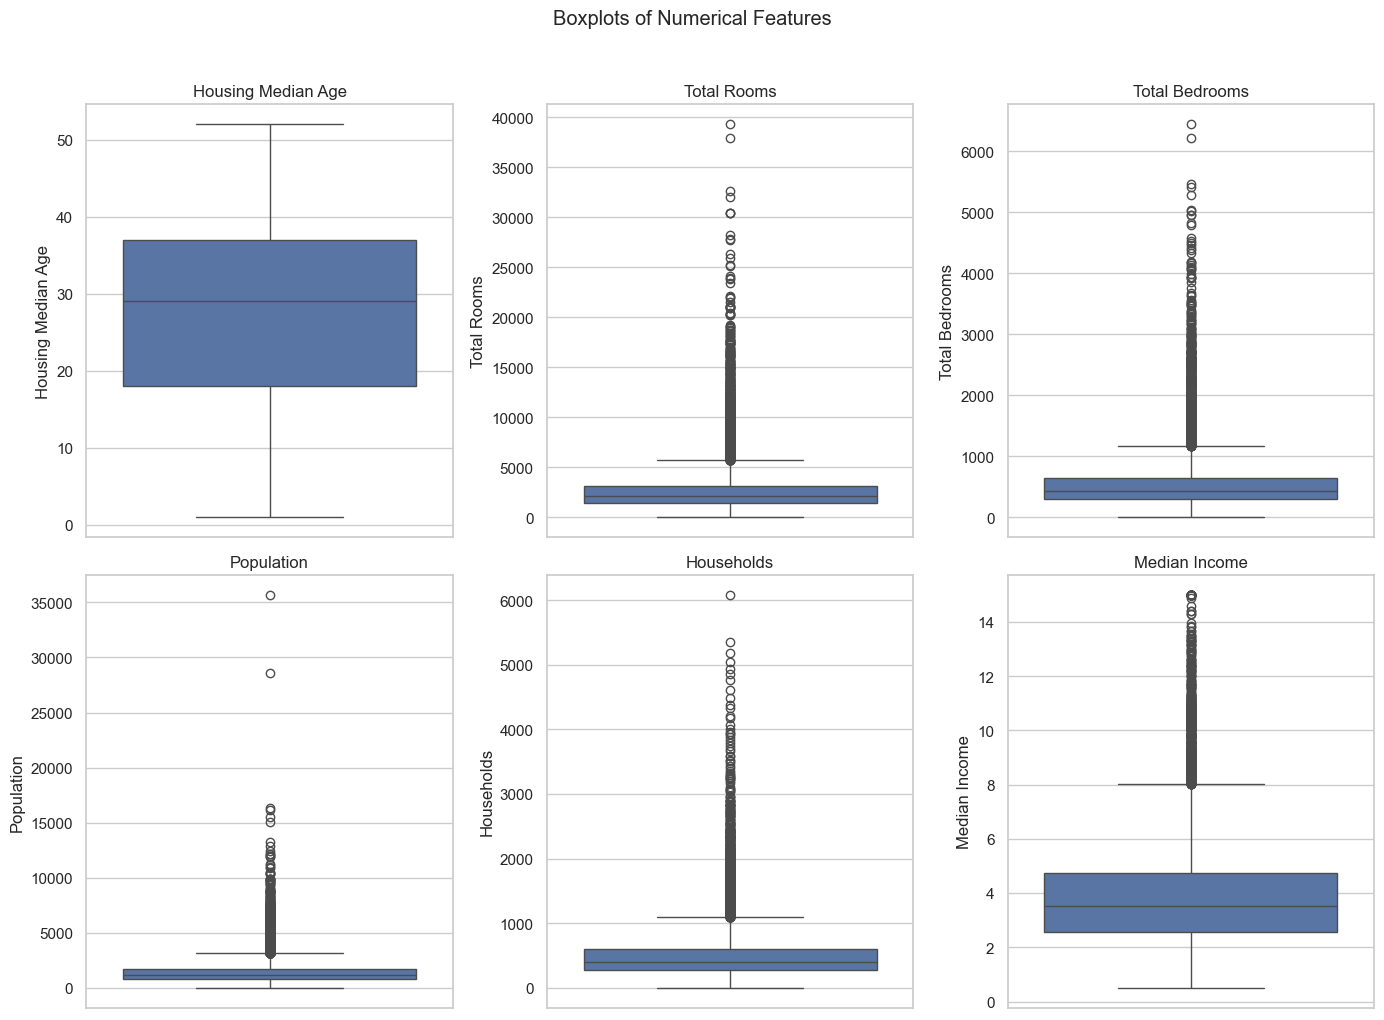

In [12]:
# Inspect potential outliers in the original numerical predictors.
numeric_boxplot_columns = [
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
]

fig, axes = plt.subplots(2, 3, figsize=(14, 10))
axes = axes.flatten()

for ax, column in zip(axes, numeric_boxplot_columns):
    sns.boxplot(data=df, y=column, ax=ax)
    ax.set_title(column.replace("_", " ").title())
    ax.set_ylabel(column.replace("_", " ").title())

fig.suptitle("Boxplots of Numerical Features", y=1.02)
fig.tight_layout()

save_figure(fig, "07_numerical_feature_boxplots.png")
plt.show()
plt.close(fig)

Saved visualization: visualizations\08_geographical_house_price_distribution.png


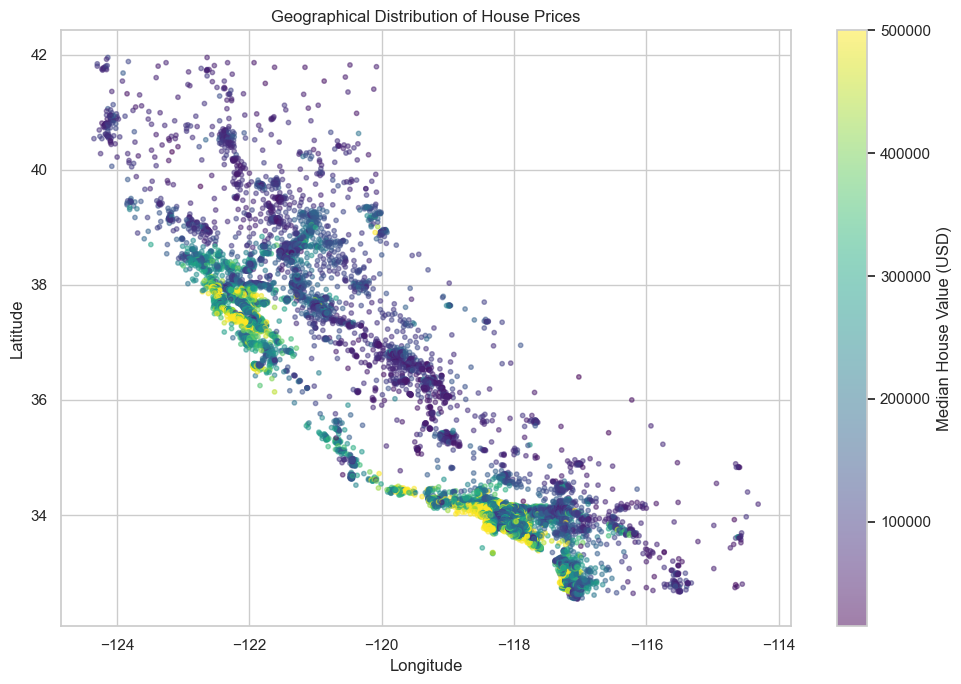

In [13]:
# Visualize the geographical distribution of house values.
fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    df["longitude"],
    df["latitude"],
    c=df[TARGET],
    cmap="viridis",
    s=10,
    alpha=0.5,
)

fig.colorbar(scatter, ax=ax, label="Median House Value (USD)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Geographical Distribution of House Prices")
fig.tight_layout()

save_figure(fig, "08_geographical_house_price_distribution.png")
plt.show()
plt.close(fig)

## 6. Data preparation and feature engineering

The target remains `median_house_value`. The original three engineered features are retained:

- `rooms_per_household`
- `bedrooms_per_room`
- `population_per_household`

The original notebook imputed missing bedrooms, created these ratios, one-hot encoded `ocean_proximity`, and standardized numerical features. The revised notebook performs these same operations inside a scikit-learn pipeline so each transformation is learned from training data only.

In [14]:
# Separate the raw predictors and target before splitting the data.
# Keep the categorical ocean_proximity column in its original form here.
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

NUMERIC_FEATURES = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household",
]

CATEGORICAL_FEATURES = ["ocean_proximity"]

print("Raw predictor shape:", X.shape)
print("Target shape:", y.shape)
print("Numeric features after engineering:", len(NUMERIC_FEATURES))
print("Categorical features:", CATEGORICAL_FEATURES)

Raw predictor shape: (20640, 9)
Target shape: (20640,)
Numeric features after engineering: 11
Categorical features: ['ocean_proximity']


## 7. Train-test split

Use the original 80:20 split and `random_state=42`. The split is performed before fitting imputers, encoders, or scalers.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

print("Training predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training predictors: (16512, 9)
Testing predictors: (4128, 9)
Training target: (16512,)
Testing target: (4128,)


## 8. Preprocessing pipeline

The preprocessing pipeline retains the original methodology while preventing leakage:

1. Learn the `total_bedrooms` median from the current training data.
2. Create the three original ratio features.
3. Impute any remaining numeric missing values with the median.
4. Standardize numerical features.
5. One-hot encode `ocean_proximity`, ignoring categories not seen during fitting.

In [16]:
def build_preprocessor():
    """Create a fresh preprocessing stage for one model or CV fold."""
    numeric_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )

    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    )

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, NUMERIC_FEATURES),
            ("categorical", categorical_encoder, CATEGORICAL_FEATURES),
        ],
        remainder="drop",
    )


def build_model_pipeline(estimator):
    """Combine learned feature engineering, preprocessing, and an estimator."""
    return Pipeline(
        steps=[
            ("feature_engineering", HousingFeatureEngineer()),
            ("preprocessor", build_preprocessor()),
            ("model", estimator),
        ]
    )

print("Preprocessing and model-pipeline builders are ready.")

Preprocessing and model-pipeline builders are ready.


## 9. Model building and training

Compare the same five regression algorithms used in the original project:

- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor
- Gradient Boosting Regressor
- HistGradientBoostingRegressor

Each model receives the raw training features and performs its preprocessing within its own pipeline.

In [17]:
regression_models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=RANDOM_STATE,
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=RANDOM_STATE,
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.1,
        random_state=RANDOM_STATE,
    ),
}

print("Models configured:")
for model_name in regression_models:
    print("-", model_name)

Models configured:
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- Hist Gradient Boosting


In [18]:
# Fit each complete pipeline and calculate the original regression metrics.
baseline_results = []
baseline_predictions = {}
fitted_pipelines = {}

for model_name, estimator in regression_models.items():
    print(f"Training: {model_name}")

    model_pipeline = build_model_pipeline(estimator)
    model_pipeline.fit(X_train, y_train)

    predictions_for_model = model_pipeline.predict(X_test)

    fitted_pipelines[model_name] = model_pipeline
    baseline_predictions[model_name] = predictions_for_model

    mae_value = mean_absolute_error(y_test, predictions_for_model)
    mse_value = mean_squared_error(y_test, predictions_for_model)
    rmse_value = np.sqrt(mse_value)
    r2_value = r2_score(y_test, predictions_for_model)

    baseline_results.append({
        "Model": model_name,
        "MAE": mae_value,
        "MSE": mse_value,
        "RMSE": rmse_value,
        "R2 Score": r2_value,
    })

print("Baseline model training completed.")

Training: Linear Regression
Training: Decision Tree
Training: Random Forest
Training: Gradient Boosting
Training: Hist Gradient Boosting
Baseline model training completed.


In [19]:
# Rank the models by R2 score, from highest to lowest.
results_df = (
    pd.DataFrame(baseline_results)
    .sort_values(by="R2 Score", ascending=False)
    .reset_index(drop=True)
)

display(results_df.style.format({
    "MAE": "{:,.2f}",
    "MSE": "{:,.2f}",
    "RMSE": "{:,.2f}",
    "R2 Score": "{:.4f}",
}))

,Model,MAE,MSE,RMSE,R2 Score
0,Hist Gradient Boosting,"30,841.83","2,150,950,557.66","46,378.34",0.8359
1,Random Forest,"32,325.26","2,532,578,201.92","50,324.73",0.8067
2,Gradient Boosting,"36,493.67","2,863,514,406.40","53,511.82",0.7815
3,Decision Tree,"43,803.51","5,120,584,623.20","71,558.26",0.6092
4,Linear Regression,"50,898.74","5,285,482,803.27","72,701.33",0.5967


Saved visualization: visualizations\09_regression_model_performance_comparison.png


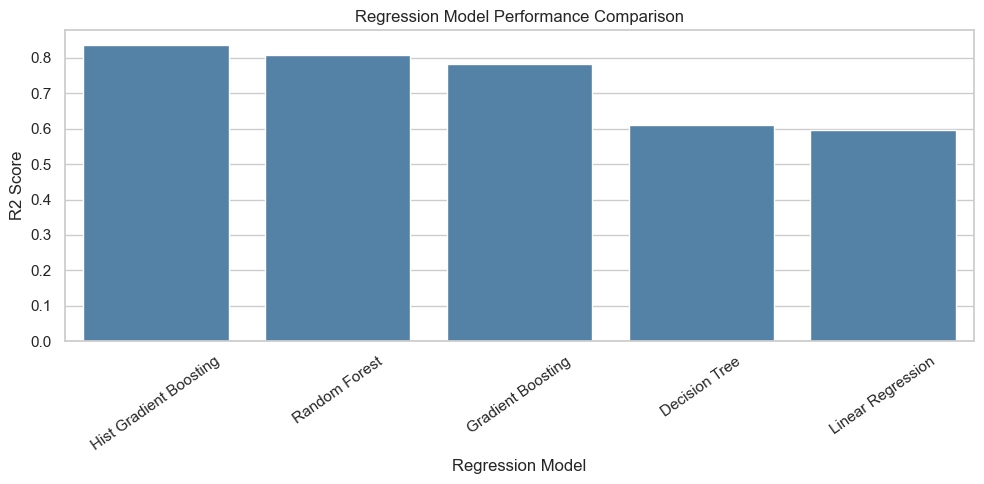

In [20]:
# Compare baseline R2 scores for all five regression models.
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    color="steelblue",
    data=results_df,
    x="Model",
    y="R2 Score",
    ax=ax,
)

ax.set_title("Regression Model Performance Comparison")
ax.set_xlabel("Regression Model")
ax.set_ylabel("R2 Score")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()

save_figure(fig, "09_regression_model_performance_comparison.png")
plt.show()
plt.close(fig)

## 10. Baseline model inspection

Identify the highest-scoring baseline model and inspect its predictions against the held-out actual values.

In [21]:
best_baseline_row = results_df.iloc[0]
best_baseline_name = best_baseline_row["Model"]
best_baseline_prediction = baseline_predictions[best_baseline_name]

print("Best baseline model:", best_baseline_name)
print(f"Baseline R2 score: {best_baseline_row['R2 Score']:.6f}")

Best baseline model: Hist Gradient Boosting
Baseline R2 score: 0.835857


Saved visualization: visualizations\10_baseline_actual_vs_predicted.png


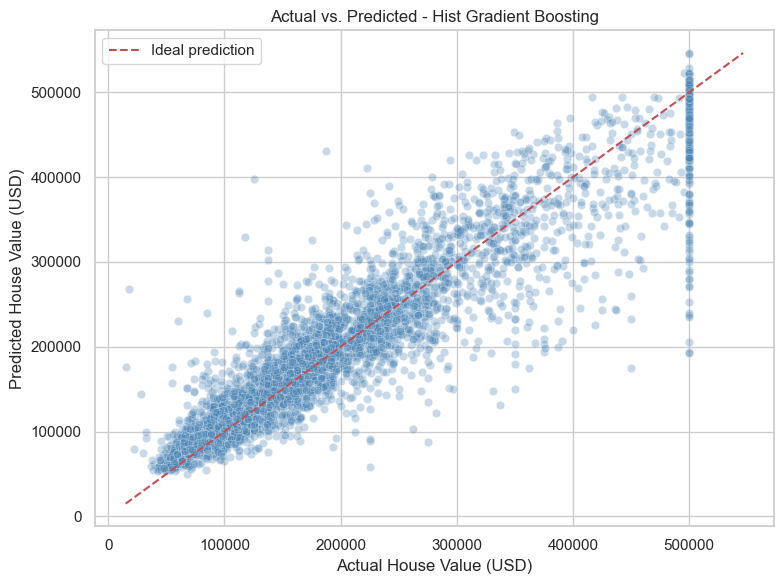

In [22]:
# Plot actual versus predicted values for the best baseline model.
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    color="steelblue",
    x=y_test,
    y=best_baseline_prediction,
    alpha=0.3,
    ax=ax,
)

axis_min = min(y_test.min(), best_baseline_prediction.min())
axis_max = max(y_test.max(), best_baseline_prediction.max())
ax.plot([axis_min, axis_max], [axis_min, axis_max], "r--", label="Ideal prediction")

ax.set_xlabel("Actual House Value (USD)")
ax.set_ylabel("Predicted House Value (USD)")
ax.set_title(f"Actual vs. Predicted - {best_baseline_name}")
ax.legend()
fig.tight_layout()

save_figure(fig, "10_baseline_actual_vs_predicted.png")
plt.show()
plt.close(fig)

## 11. Hyperparameter tuning

Tune `HistGradientBoostingRegressor` using the original search space, 30 randomized candidates, 5-fold cross-validation, R2 scoring, and `random_state=42`.

The search is applied to the complete pipeline. Therefore, each cross-validation fold independently learns its imputation, feature engineering, encoding, and scaling parameters.

In [ ]:
hist_pipeline = build_model_pipeline(
    HistGradientBoostingRegressor(random_state=RANDOM_STATE)
)

param_distributions = {
    "model__max_iter": [100, 200, 300, 500],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "model__max_leaf_nodes": [15, 31, 50, 100],
    "model__max_depth": [None, 5, 10, 15],
    "model__l2_regularization": [0, 0.1, 1, 5],
}

random_search = RandomizedSearchCV(
    estimator=hist_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="r2",
    cv=5,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    refit=True,
)

random_search.fit(X_train, y_train)

print("Hyperparameter search completed.")

Fitting 5 folds for each of 30 candidates, totalling 150 fits


In [ ]:
print("Best hyperparameters:")
best_parameters = random_search.best_params_
display(pd.Series(best_parameters, name="Selected Value").to_frame())

print(f"Best cross-validation R2 score: {random_search.best_score_:.6f}")

## 12. Tuned model evaluation

Evaluate the refitted best pipeline once on the held-out test set. MAE, MSE, RMSE, and R2 are calculated using the same definitions as the baseline comparison.

In [ ]:
best_pipeline = random_search.best_estimator_
y_pred_tuned = best_pipeline.predict(X_test)

tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_mse = mean_squared_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_pred_tuned)

tuned_metrics = {
    "MAE": tuned_mae,
    "MSE": tuned_mse,
    "RMSE": tuned_rmse,
    "R2 Score": tuned_r2,
}

print("Tuned HistGradientBoosting test-set metrics:")
display(pd.Series(tuned_metrics, name="Value").to_frame())

In [ ]:
# Compare the original HistGradientBoosting baseline with the tuned pipeline.
baseline_hist_row = results_df.loc[
    results_df["Model"] == "Hist Gradient Boosting"
].iloc[0]

comparison = pd.DataFrame([
    {
        "Model": "Original HistGB",
        "R2 Score": baseline_hist_row["R2 Score"],
        "RMSE": baseline_hist_row["RMSE"],
        "MAE": baseline_hist_row["MAE"],
    },
    {
        "Model": "Tuned HistGB",
        "R2 Score": tuned_r2,
        "RMSE": tuned_rmse,
        "MAE": tuned_mae,
    },
])

display(comparison.style.format({
    "R2 Score": "{:.4f}",
    "RMSE": "{:,.2f}",
    "MAE": "{:,.2f}",
}))

In [ ]:
# Visualize the R2 score before and after tuning.
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    color="steelblue",
    data=comparison,
    x="Model",
    y="R2 Score",
    ax=ax,
)

ax.set_title("HistGradientBoosting: Before vs. After Hyperparameter Tuning")
ax.set_xlabel("Model")
ax.set_ylabel("R2 Score")
ax.set_ylim(0, 1)
fig.tight_layout()

save_figure(fig, "11_hist_gradient_boosting_tuning_comparison.png")
plt.show()
plt.close(fig)

In [ ]:
# Check how closely the tuned model's predictions match actual house values.
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    color="steelblue",
    x=y_test,
    y=y_pred_tuned,
    alpha=0.3,
    ax=ax,
)

axis_min = min(y_test.min(), y_pred_tuned.min())
axis_max = max(y_test.max(), y_pred_tuned.max())
ax.plot([axis_min, axis_max], [axis_min, axis_max], "r--", label="Ideal prediction")

ax.set_xlabel("Actual House Value (USD)")
ax.set_ylabel("Predicted House Value (USD)")
ax.set_title("Actual vs. Predicted House Values (Tuned HistGB)")
ax.legend()
fig.tight_layout()

save_figure(fig, "12_tuned_actual_vs_predicted.png")
plt.show()
plt.close(fig)

In [ ]:
# Residuals are actual values minus predicted values.
residuals = y_test - y_pred_tuned

fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    color="steelblue",
    x=y_pred_tuned,
    y=residuals,
    alpha=0.3,
    ax=ax,
)

ax.axhline(0, color="red", linestyle="--")
ax.set_xlabel("Predicted House Value (USD)")
ax.set_ylabel("Residual (Actual - Predicted)")
ax.set_title("Residual Plot - Tuned HistGB")
fig.tight_layout()

save_figure(fig, "13_tuned_model_residual_plot.png")
plt.show()
plt.close(fig)

## 13. Feature importance

Use permutation importance on the transformed held-out test data. This evaluates how much the fitted model's R2 score decreases when each transformed feature is shuffled.

In [ ]:
# Apply the already-fitted feature engineering and preprocessing steps to test data.
engineered_test = best_pipeline.named_steps["feature_engineering"].transform(X_test)
processed_test = best_pipeline.named_steps["preprocessor"].transform(engineered_test)

transformed_feature_names = (
    best_pipeline.named_steps["preprocessor"].get_feature_names_out()
)

importance = permutation_importance(
    estimator=best_pipeline.named_steps["model"],
    X=processed_test,
    y=y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

importance_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": importance.importances_mean,
    "Importance Std": importance.importances_std,
}).sort_values(
    by="Importance",
    ascending=False,
).reset_index(drop=True)

display(importance_df.head(15))

In [ ]:
# Plot the 15 most influential transformed features.
top_features = importance_df.head(15).sort_values("Importance", ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(
    color="steelblue",
    data=top_features,
    x="Importance",
    y="Feature",
    ax=ax,
)

ax.set_title("Top 15 Important Features - Tuned HistGB")
ax.set_xlabel("Mean Decrease in R2 After Permutation")
ax.set_ylabel("Transformed Feature")
fig.tight_layout()

save_figure(fig, "14_tuned_model_top_15_feature_importance.png")
plt.show()
plt.close(fig)

## 14. Final results and prediction review

Review the tuned model's final test metrics and create a row-by-row actual-versus-predicted table. The results are calculated from the executed model; no metric values are hard-coded.

In [ ]:
final_results = pd.DataFrame(
    [
        {
            "Model": "Tuned HistGradientBoosting",
            "MAE": tuned_mae,
            "MSE": tuned_mse,
            "RMSE": tuned_rmse,
            "R2 Score": tuned_r2,
        }
    ]
)

display(final_results.style.format({
    "MAE": "{:,.2f}",
    "MSE": "{:,.2f}",
    "RMSE": "{:,.2f}",
    "R2 Score": "{:.4f}",
}))

prediction_result = pd.DataFrame(
    {
        "Actual Price": y_test,
        "Predicted Price": y_pred_tuned,
    },
    index=y_test.index,
)

prediction_result["Absolute Error"] = (
    prediction_result["Actual Price"] - prediction_result["Predicted Price"]
).abs()

display(prediction_result.head(10))

## 15. Model saving and exporting

Save the complete fitted pipeline. It includes the training-learned bedroom median, feature engineering, numeric imputation, scaling, categorical encoding, and tuned estimator. This allows predictions from the original, unencoded input columns.

In [ ]:
MODEL_PATH = MODEL_DIR / "Housing_Price_Prediction_System.pkl"

joblib.dump(best_pipeline, MODEL_PATH)

# Export reproducible evaluation artifacts alongside the model.
results_df.to_csv(MODEL_DIR / "baseline_model_comparison.csv", index=False)
comparison.to_csv(MODEL_DIR / "hist_gradient_boosting_comparison.csv", index=False)
importance_df.to_csv(MODEL_DIR / "permutation_feature_importance.csv", index=False)
prediction_result.to_csv(MODEL_DIR / "tuned_model_test_predictions.csv", index=True)

dataset_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()

model_metadata = {
    "project": "California Housing Price Prediction",
    "dataset_file": "Dataset/housing.csv",
    "dataset_sha256": dataset_sha256,
    "target": TARGET,
    "test_size": 0.2,
    "random_state": RANDOM_STATE,
    "cross_validation_folds": 5,
    "randomized_search_iterations": 30,
    "best_parameters": best_parameters,
    "test_metrics": tuned_metrics,
    "best_cross_validation_r2": float(random_search.best_score_),
    "python_scikit_learn_version": sklearn.__version__,
}

with (MODEL_DIR / "model_metadata.json").open("w", encoding="utf-8") as metadata_file:
    json.dump(model_metadata, metadata_file, indent=4, default=str)

print(f"Complete model pipeline saved to: {MODEL_PATH.relative_to(PROJECT_ROOT)}")
print("Evaluation tables, predictions, feature importance, and metadata exported.")

## 16. Load the exported model and verify prediction

Reload the saved pipeline and run a prediction using one raw test observation. The model accepts the original columns, including the unencoded `ocean_proximity` category.

In [ ]:
loaded_model = joblib.load(MODEL_PATH)
print("Saved model loaded successfully.")

sample_house = X_test.iloc[[0]].copy()
sample_prediction = float(loaded_model.predict(sample_house)[0])
sample_actual = float(y_test.iloc[0])

print(f"Actual house value:    ${sample_actual:,.2f}")
print(f"Predicted house value: ${sample_prediction:,.2f}")
print(f"Absolute error:        ${abs(sample_actual - sample_prediction):,.2f}")

## 17. Reusable prediction functions

`predict_house_price()` accepts a DataFrame containing the original predictor columns. `house_price_predictor()` provides an optional interactive console interface. The interactive function is defined but not automatically called, so executing the notebook will not pause for user input.

In [ ]:
def predict_house_price(data):
    """Predict house value from one or more rows of raw housing features.

    Parameters
    ----------
    data : pandas.DataFrame
        Must contain the original predictor columns, including ocean_proximity.

    Returns
    -------
    numpy.ndarray
        Predicted median house values.
    """
    required_columns = X.columns.tolist()
    missing_columns = [column for column in required_columns if column not in data.columns]

    if missing_columns:
        raise ValueError(f"Missing required input columns: {missing_columns}")

    return loaded_model.predict(data[required_columns])


def house_price_predictor():
    """Collect one housing record from the console and estimate its value."""
    valid_categories = sorted(df["ocean_proximity"].dropna().unique().tolist())

    print("Enter the property information.")
    print("Valid ocean proximity categories:", ", ".join(valid_categories))

    longitude = float(input("Longitude: "))
    latitude = float(input("Latitude: "))
    age = float(input("House age: "))
    rooms = float(input("Total rooms: "))
    bedrooms = float(input("Total bedrooms: "))
    population = float(input("Population: "))
    households = float(input("Households: "))
    income = float(input("Median income: "))
    ocean_proximity = input("Ocean proximity: ").strip()

    if rooms <= 0 or households <= 0:
        raise ValueError("Total rooms and households must be greater than zero.")

    if ocean_proximity not in valid_categories:
        raise ValueError(
            f"Invalid ocean proximity. Choose one of: {', '.join(valid_categories)}"
        )

    raw_input_data = pd.DataFrame({
        "longitude": [longitude],
        "latitude": [latitude],
        "housing_median_age": [age],
        "total_rooms": [rooms],
        "total_bedrooms": [bedrooms],
        "population": [population],
        "households": [households],
        "median_income": [income],
        "ocean_proximity": [ocean_proximity],
    })

    estimated_value = float(predict_house_price(raw_input_data)[0])
    print(f"Estimated house value: ${estimated_value:,.2f}")


# To use the interactive console predictor, run this in a separate cell:
# house_price_predictor()

## 18. Conclusion

This project compared five regression algorithms for California housing-value prediction and tuned HistGradientBoostingRegressor using randomized search with five-fold cross-validation.

The notebook preserves the original target, dataset, train-test split settings, feature-engineering definitions, model families, evaluation metrics, and hyperparameter search space. Preprocessing is now fitted within the model pipeline to avoid leakage. All 14 project visualizations are saved as 300-DPI PNG files in `visualizations/`.

The final test metrics and selected hyperparameters are generated during notebook execution. Interpret the results in the context of this dataset and its district-level target; they should not be treated as guaranteed market prices for individual properties.